In [28]:
import pandas as pd

In [29]:
df_PD = pd.read_csv('~/MinaRyten/Melissa/MRIxST/stats/04c-4layers_PDpredictions_withendo_with_PrD/Projected_PD_ACG_cell_counts_no_SWM.csv')



In [30]:
df_control = pd.read_csv('~/MinaRyten/Melissa/MRIxST/processed_data/01b-4layers_withendo/02-top3_cells_counts/top3_cells_per_layer_count.csv', index_col = 0)

In [31]:
df_control['region'] = df_control['sample_id'].str.split('_', expand = True)[1]
df_control = df_control.groupby(['bayesSpace_harmony_7', 'variable', 'region']).median()
df_control.reset_index(inplace = True)
df_control.replace({'ant':'anterior', 'mid':'middle', 'post':'posterior'}, inplace = True)

In [32]:
df_PD = pd.melt(df_PD, id_vars=['SpD', 'region'], value_vars=['Astro_PD_predicted', 'Micro_PD_predicted', 'Oligo_PD_predicted', 'OPC_PD_predicted'])
df_PD['celltype'] = df_PD['variable'].str.split('_', expand = True)[0]
df_PD.rename(columns = { 'value':'PD - predicted counts'}, inplace = True)

In [33]:
df_control.rename(columns = {'bayesSpace_harmony_7':'SpD', 'variable':'celltype', 'value':'Control - real counts'}, inplace = True)
df_control = df_control[df_control['SpD']!='WM']
df_control['key'] = df_control['SpD']+df_control['celltype']+df_control['region']

In [34]:
df_PD = df_PD[['SpD','celltype','region', 'PD - predicted counts']]
df_PD['key'] = df_PD['SpD']+df_PD['celltype']+df_PD['region']

In [35]:
#df = pd.concat([df_control, df_PD])

combined = df_PD.merge(df_control[['key', 'Control - real counts']], left_on = 'key', right_on = 'key', how = 'inner')
combined.drop(columns = 'key', inplace = True)

Cell type: Astro
R²: 0.16060165983397046
p-value: 0.19669803723959692


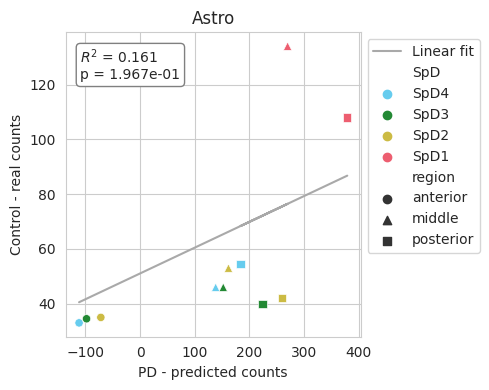

Cell type: Micro
R²: 0.07740102474552435
p-value: 0.38125589089886425


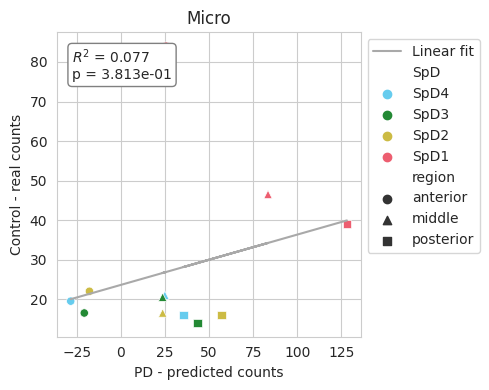

Cell type: Oligo
R²: 0.04602800909281002
p-value: 0.5031159952291059


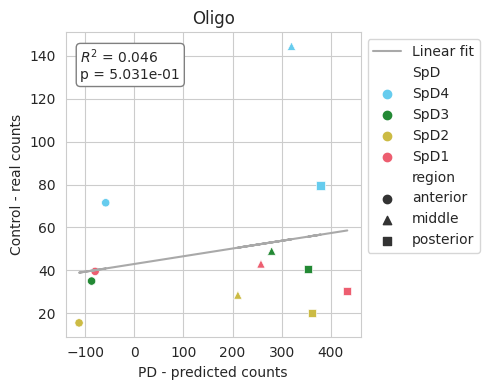

Cell type: OPC
R²: 0.13359521136029784
p-value: 0.24266309057456148


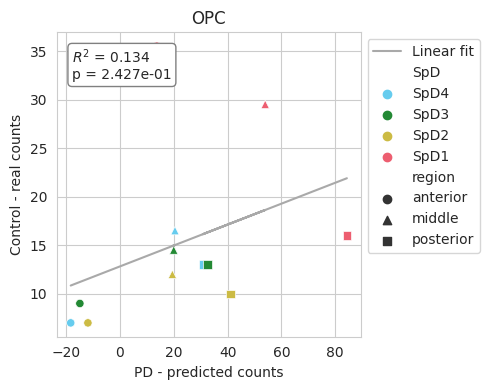

In [36]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from statsmodels.stats.multitest import fdrcorrection as fdr

custom_palette = {
    'SpD1': '#ED5E70',  # blue
    'SpD2': '#CCBB44',  # orange
    'SpD3': '#238934',  # green
    'SpD4': '#66CCEE'   # red
}

marker_dict = {
    'anterior': 'o',   # circle
    'middle': '^',     # triangle
    'posterior': 's'   # square
}


sns.set_style("whitegrid")

for cell in combined['celltype'].unique():
    res = []
    print(f"Cell type: {cell}")
    
    # Subset data
    df = combined[combined['celltype'] == cell]
    X = np.asarray(df["PD - predicted counts"]).reshape(-1, 1)
    Y = np.asarray(df["Control - real counts"]).reshape(-1, 1)
    
    # Fit model
    model = LinearRegression().fit(X, Y)
    
    # R² score
    r_squared = model.score(X, Y)
    print("R²:", r_squared)
    
    
    # Add intercept
    X_sm = sm.add_constant(X)
    sm_model = sm.OLS(Y, X_sm).fit()
    p_value = sm_model.pvalues[1]  # p-value for the slope
    print("p-value:", p_value)
    
    r2_text = f"$R^2$ = {r_squared:.3f}"
    pval_text = f"p = {p_value:.3e}"

    res.append(cell)
    res.append(r_squared)
    res.append(p_value)
    
    # Plot
    plt.figure(figsize=(5, 4))
    plt.plot(X, model.predict(X), color='darkgrey', label='Linear fit')
    ax = sns.scatterplot(x=df["PD - predicted counts"], y=df["Control - real counts"], hue=df["SpD"], palette = custom_palette, style=df["region"], markers=marker_dict)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    plt.title(f"{cell}")
    plt.xlabel("PD - predicted counts")
    plt.ylabel("Control - real counts")
    plt.tight_layout()
    
    plt.text(
    x=0.05, y=0.95,               # relative position in axes coordinates
    s=f"{r2_text}\n{pval_text}", # multiline annotation
    transform=plt.gca().transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray"))
    plt.show()
    
    if (cell == 'Astro'):
        full_results = pd.DataFrame(res).T
    else:
        full_results = pd.concat([full_results, pd.DataFrame(res).T])



Cell type: Astro
R²: 0.20664941987375052
p-value: 0.13761732467152352


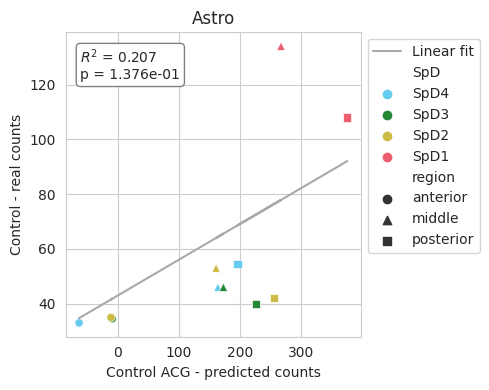

Cell type: Micro
R²: 0.16996198588289801
p-value: 0.1829409870247048


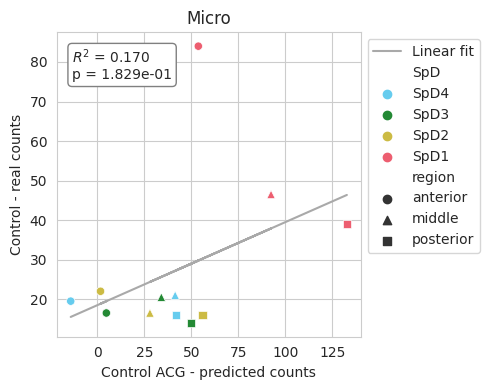

Cell type: Oligo
R²: 0.03061894961058209
p-value: 0.5864812815104286


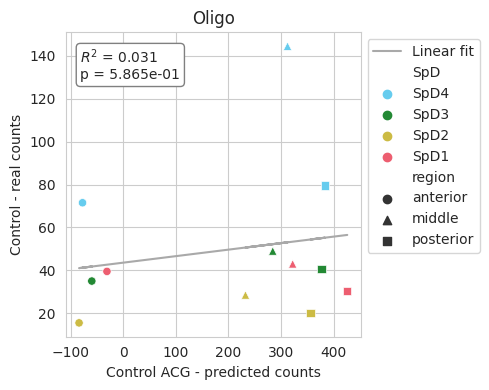

Cell type: OPC
R²: 0.22085599059200767
p-value: 0.12316097998202494


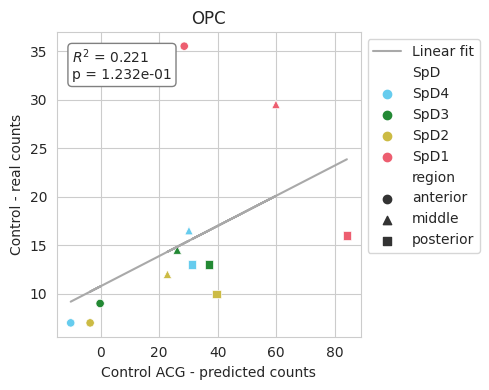

In [40]:
df_acg = pd.read_csv('~/MinaRyten/Melissa/MRIxST/stats/04c-4layers_PDpredictions_withendo_with_PrD/Projected_control_ACG_cell_counts_no_SWM.csv')
df_control = pd.read_csv('~/MinaRyten/Melissa/MRIxST/processed_data/01b-4layers_withendo/02-top3_cells_counts/top3_cells_per_layer_count.csv', index_col = 0)

df_control['region'] = df_control['sample_id'].str.split('_', expand = True)[1]
df_control = df_control.groupby(['bayesSpace_harmony_7', 'variable', 'region']).median()
df_control.reset_index(inplace = True)
df_control.replace({'ant':'anterior', 'mid':'middle', 'post':'posterior'}, inplace = True)
df_acg = pd.melt(df_acg, id_vars=['SpD', 'region'], value_vars=['Astro_Control_predicted', 'Micro_Control_predicted', 'Oligo_Control_predicted', 'OPC_Control_predicted'])
df_acg['celltype'] = df_acg['variable'].str.split('_', expand = True)[0]
df_acg.rename(columns = { 'value':'Control ACG - predicted counts'}, inplace = True)
df_control.rename(columns = {'bayesSpace_harmony_7':'SpD', 'variable':'celltype', 'value':'Control - real counts'}, inplace = True)
df_control = df_control[df_control['SpD']!='WM']
df_control['key'] = df_control['SpD']+df_control['celltype']+df_control['region']
df_acg = df_acg[['SpD','celltype','region', 'Control ACG - predicted counts']]
df_acg['key'] = df_acg['SpD']+df_acg['celltype']+df_acg['region']
#df = pd.concat([df_control, df_PD])

combined = df_acg.merge(df_control[['key', 'Control - real counts']], left_on = 'key', right_on = 'key', how = 'inner')
combined.drop(columns = 'key', inplace = True)


custom_palette = {
    'SpD1': '#ED5E70',  # blue
    'SpD2': '#CCBB44',  # orange
    'SpD3': '#238934',  # green
    'SpD4': '#66CCEE'   # red
}

marker_dict = {
    'anterior': 'o',   # circle
    'middle': '^',     # triangle
    'posterior': 's'   # square
}


sns.set_style("whitegrid")

for cell in combined['celltype'].unique():
    res = []
    print(f"Cell type: {cell}")
    
    # Subset data
    df = combined[combined['celltype'] == cell]
    X = np.asarray(df["Control ACG - predicted counts"]).reshape(-1, 1)
    Y = np.asarray(df["Control - real counts"]).reshape(-1, 1)
    
    # Fit model
    model = LinearRegression().fit(X, Y)
    
    # R² score
    r_squared = model.score(X, Y)
    print("R²:", r_squared)
    
    
    # Add intercept
    X_sm = sm.add_constant(X)
    sm_model = sm.OLS(Y, X_sm).fit()
    p_value = sm_model.pvalues[1]  # p-value for the slope
    print("p-value:", p_value)
    
    r2_text = f"$R^2$ = {r_squared:.3f}"
    pval_text = f"p = {p_value:.3e}"

    res.append(cell)
    res.append(r_squared)
    res.append(p_value)
    
    # Plot
    plt.figure(figsize=(5, 4))
    plt.plot(X, model.predict(X), color='darkgrey', label='Linear fit')
    ax = sns.scatterplot(x=df["Control ACG - predicted counts"], y=df["Control - real counts"], hue=df["SpD"], palette = custom_palette, style=df["region"], markers=marker_dict)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    plt.title(f"{cell}")
    plt.xlabel("Control ACG - predicted counts")
    plt.ylabel("Control - real counts")
    plt.tight_layout()
    
    plt.text(
    x=0.05, y=0.95,               # relative position in axes coordinates
    s=f"{r2_text}\n{pval_text}", # multiline annotation
    transform=plt.gca().transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray"))
    plt.show()
    
    if (cell == 'Astro'):
        full_results = pd.DataFrame(res).T
    else:
        full_results = pd.concat([full_results, pd.DataFrame(res).T])



Cell type: Astro
R²: 0.9866202452458492
p-value: 1.0611497743781706e-10


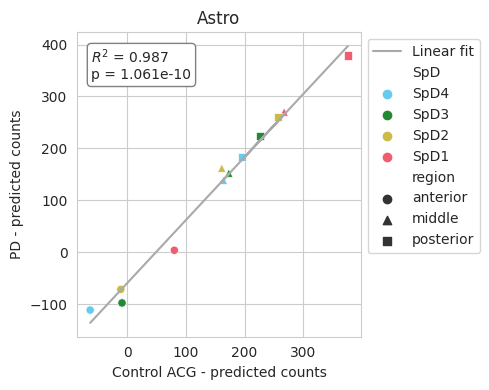

Cell type: Micro
R²: 0.9668118381183392
p-value: 1.00487152464319e-08


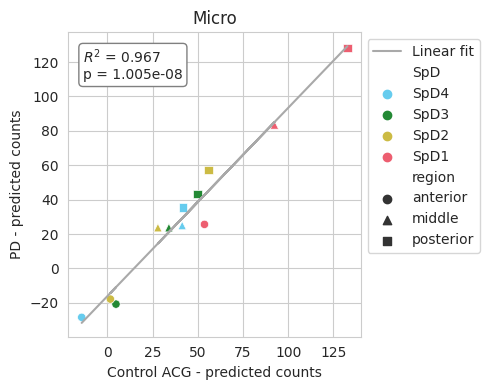

Cell type: Oligo
R²: 0.9864232192842433
p-value: 1.1417105508075316e-10


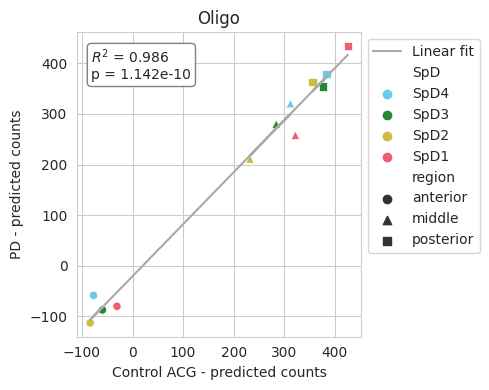

Cell type: OPC
R²: 0.9772580028031437
p-value: 1.5114720501952088e-09


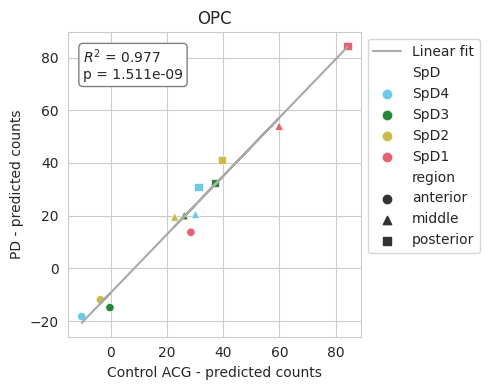

In [43]:
combined = df_acg.merge(df_PD[['key', 'PD - predicted counts']], left_on = 'key', right_on = 'key', how = 'inner')
combined.drop(columns = 'key', inplace = True)


custom_palette = {
    'SpD1': '#ED5E70',  # blue
    'SpD2': '#CCBB44',  # orange
    'SpD3': '#238934',  # green
    'SpD4': '#66CCEE'   # red
}

marker_dict = {
    'anterior': 'o',   # circle
    'middle': '^',     # triangle
    'posterior': 's'   # square
}


sns.set_style("whitegrid")

for cell in combined['celltype'].unique():
    res = []
    print(f"Cell type: {cell}")
    
    # Subset data
    df = combined[combined['celltype'] == cell]
    X = np.asarray(df["Control ACG - predicted counts"]).reshape(-1, 1)
    Y = np.asarray(df["PD - predicted counts"]).reshape(-1, 1)
    
    # Fit model
    model = LinearRegression().fit(X, Y)
    
    # R² score
    r_squared = model.score(X, Y)
    print("R²:", r_squared)
    
    
    # Add intercept
    X_sm = sm.add_constant(X)
    sm_model = sm.OLS(Y, X_sm).fit()
    p_value = sm_model.pvalues[1]  # p-value for the slope
    print("p-value:", p_value)
    
    r2_text = f"$R^2$ = {r_squared:.3f}"
    pval_text = f"p = {p_value:.3e}"

    res.append(cell)
    res.append(r_squared)
    res.append(p_value)
    
    # Plot
    plt.figure(figsize=(5, 4))
    plt.plot(X, model.predict(X), color='darkgrey', label='Linear fit')
    ax = sns.scatterplot(x=df["Control ACG - predicted counts"], y=df["PD - predicted counts"], hue=df["SpD"], palette = custom_palette, style=df["region"], markers=marker_dict)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    plt.title(f"{cell}")
    plt.xlabel("Control ACG - predicted counts")
    plt.ylabel("PD - predicted counts")
    plt.tight_layout()
    
    plt.text(
    x=0.05, y=0.95,               # relative position in axes coordinates
    s=f"{r2_text}\n{pval_text}", # multiline annotation
    transform=plt.gca().transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray"))
    plt.show()
    
    if (cell == 'Astro'):
        full_results = pd.DataFrame(res).T
    else:
        full_results = pd.concat([full_results, pd.DataFrame(res).T])
